# Exploratory Data Analysis - Smart Finance Tracker

Four sections, each ending in **Findings and Decisions**. Data: synthetic multi-user history from `src/data_prep.py`,
calibrated with MoSPI HCES 2023-24 urban shares (category mix), public dataset #2 UPI 2024 (ticket sizes, weekend pattern)
and public dataset #1 (merchant names). Public datasets #1-#3 are compared below.

> Run `python -m src.data_prep` first.

In [1]:
import sys, numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
sys.path.insert(0, str(ROOT))
from src.data_prep import load_public, EXPENSE_CATEGORIES, HCES_URBAN_SHARES
from src import features as F
sns.set_theme(style='whitegrid'); pd.set_option('display.width', 140)
RES = ROOT / 'results'; RES.mkdir(exist_ok=True)
df = pd.read_csv(ROOT / 'data/processed/transactions_clean.csv', parse_dates=['date'])
users = pd.read_csv(ROOT / 'data/raw/users.csv')
labels = pd.read_csv(ROOT / 'data/raw/recurring_labels.csv')
public = load_public()
print(df.shape, users.shape, labels.shape)

[load_public] hf_transactions.csv: (1000, 4), columns=['date', 'description', 'amount', 'category']


[load_public] upi_transactions_2024.csv: (250000, 17), columns=['transaction id', 'timestamp', 'transaction type', 'merchant_category', 'amount (INR)', 'transaction_status', 'sender_age_group', 'receiver_age_group', 'sender_state', 'sender_bank', 'receiver_bank', 'device_type', 'network_type', 'fraud_flag', 'hour_of_day', 'day_of_week', 'is_weekend']
[load_public] credit_card_india.csv: (26052, 7), columns=['index', 'City', 'Date', 'Card Type', 'Exp Type', 'Gender', 'Amount']
(349202, 13) (300, 4) (2627, 3)


## 1. Transactions

Imbalance ratio (largest / smallest class): 11.6


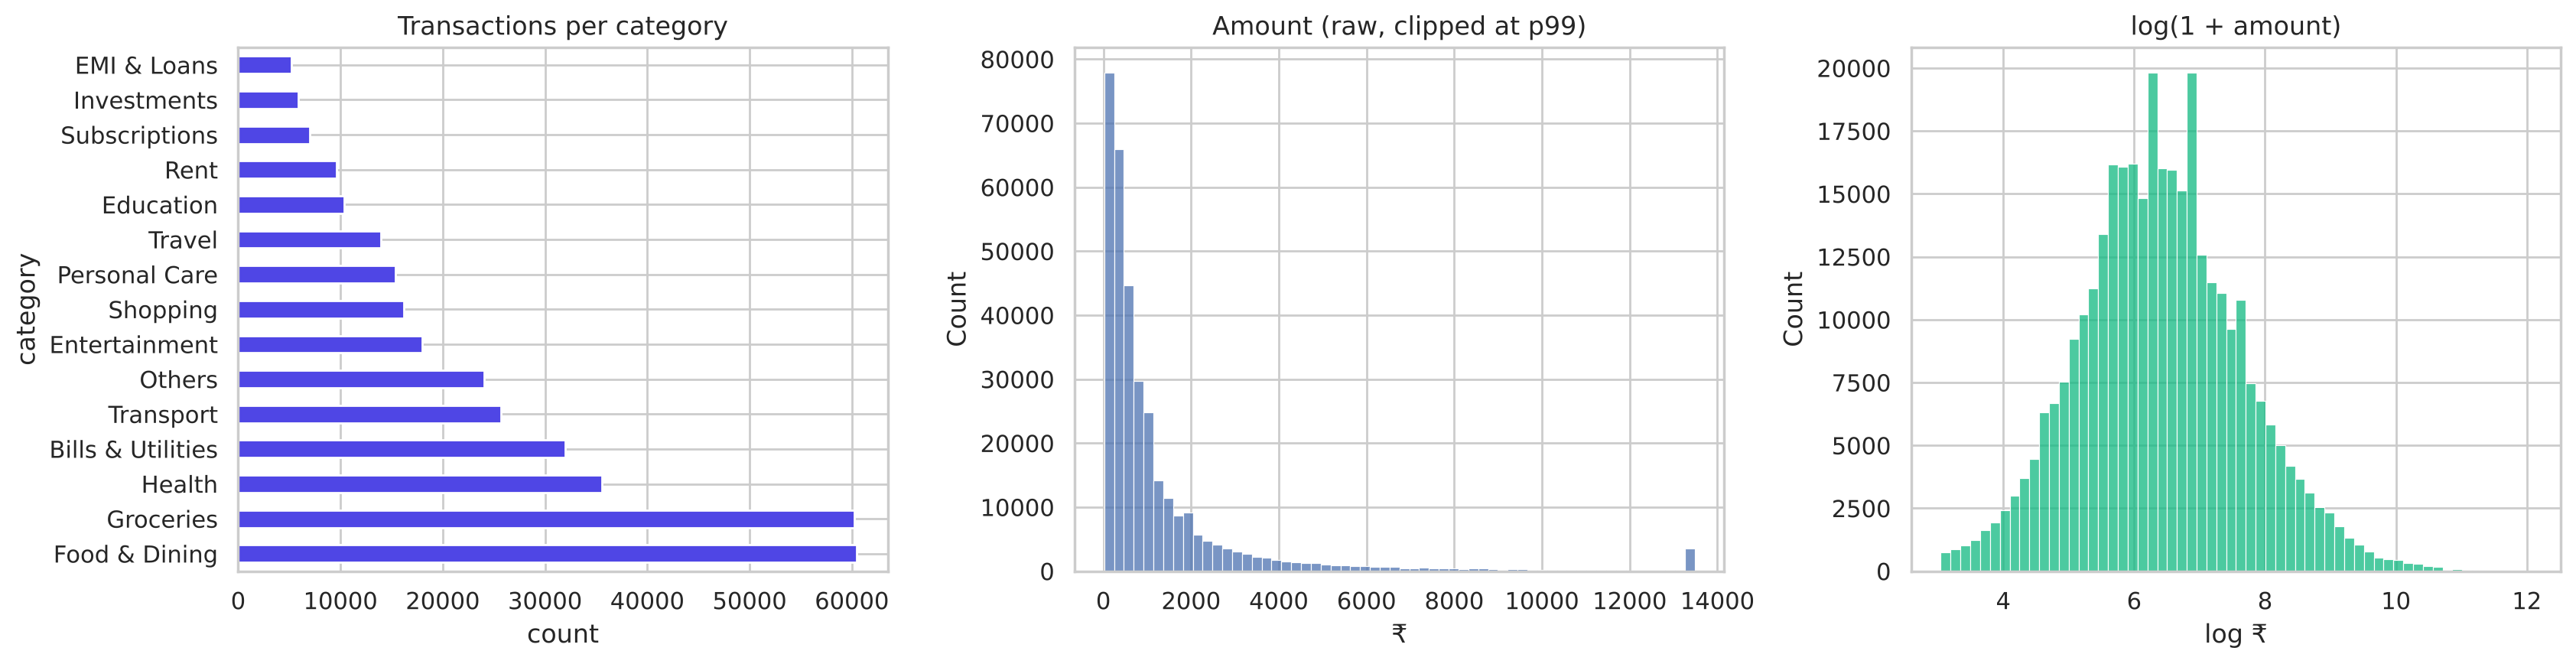

In [2]:
debit = df[df.type == 'debit']
counts = debit.category.value_counts()
print('Imbalance ratio (largest / smallest class):', round(counts.max() / counts.min(), 1))
fig, ax = plt.subplots(1, 3, figsize=(17, 4.5))
counts.plot.barh(ax=ax[0], color='#4F46E5'); ax[0].set(title='Transactions per category', xlabel='count')
sns.histplot(debit.amount.clip(upper=debit.amount.quantile(.99)), bins=60, ax=ax[1]); ax[1].set(title='Amount (raw, clipped at p99)', xlabel='₹')
sns.histplot(debit.log_amount, bins=60, ax=ax[2], color='#10B981'); ax[2].set(title='log(1 + amount)', xlabel='log ₹')
plt.tight_layout(); plt.savefig(RES / 'eda_category_counts_amounts.png', dpi=110); plt.show()

In [3]:
print('Payment mode share:'); print(df.payment_mode.value_counts(normalize=True).round(3))
print('\nMissing values:'); print(df.isna().sum()[df.isna().sum() > 0])
print('Exact duplicate rows:', df.duplicated(subset=['user_id','date','description','amount']).sum())
print('Rows whose cleaned description is "unknown":', (df.clean_desc == 'unknown').sum())

Payment mode share:
payment_mode
UPI      0.581
CARD     0.163
POS      0.163
ACH      0.032
NEFT     0.020
ATM      0.018
OTHER    0.014
IMPS     0.009
Name: proportion, dtype: float64

Missing values:
Series([], dtype: int64)
Exact duplicate rows: 0
Rows whose cleaned description is "unknown": 0


In [4]:
from collections import Counter
top = {c: [w for w, _ in Counter(' '.join(g.clean_desc).split()).most_common(5)] for c, g in debit.groupby('category')}
pd.DataFrame(top).T

,0,1,2,3,4
Bills & Utilities,airtel,jio,gas,bescom,electricity
EMI & Loans,loan,bajaj,finserv,kreditbee,icici
Education,fees,vedantu,coursera,byjus,unacademy
Entertainment,wonderla,bookmyshow,pvr,playstation,inox
Food & Dining,zomato,theobroma,mcdonalds,dominos,starbucks
Groceries,zepto,bigbasket,jiomart,blinkit,spencers
Health,medplus,dentist,pharmeasy,practo,thyrocare
Investments,mf,sip,groww,zerodha,axis
Others,atm,paytm,wallet,amazon,gift
Personal Care,fit,cult,salon,purplle,nykaa


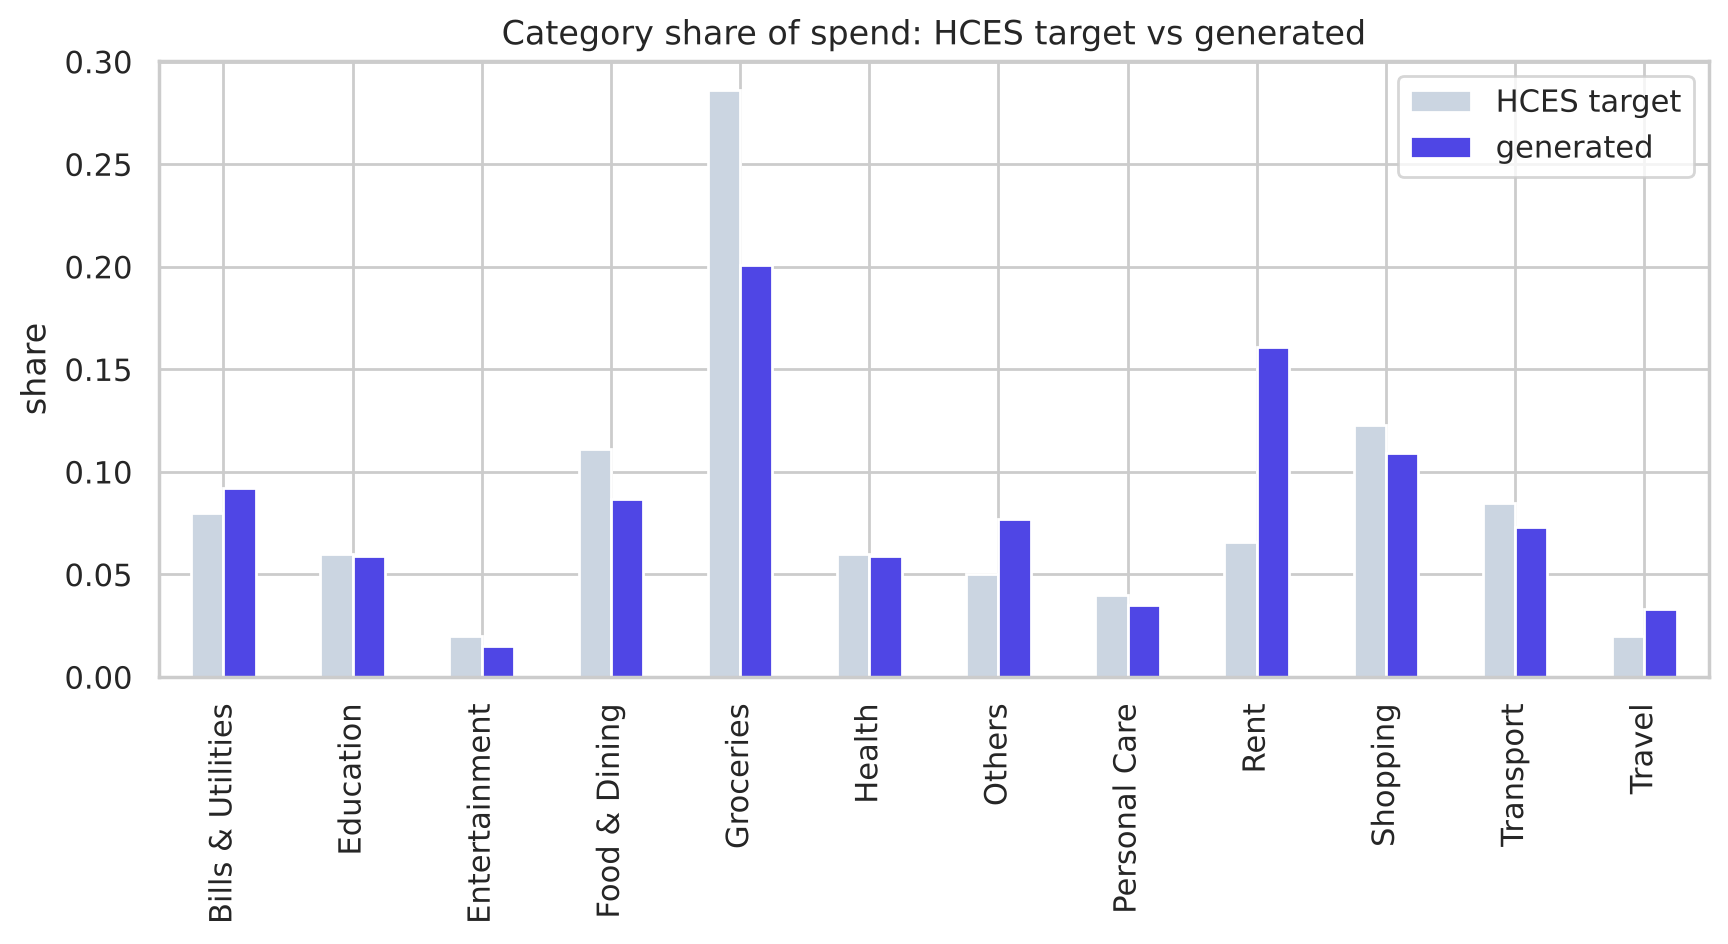

,HCES target,generated
Bills & Utilities,0.080,0.092
Education,0.060,0.059
Entertainment,0.020,0.015
Food & Dining,0.111,0.087
Groceries,0.286,0.201
Health,0.060,0.059
Others,0.050,0.077
Personal Care,0.040,0.035
Rent,0.066,0.161
Shopping,0.123,0.109


In [5]:
# share of spend vs HCES-based target (urban)
target = pd.Series(HCES_URBAN_SHARES); target /= target.sum()
actual = debit[debit.category.isin(target.index)].groupby('category').amount.sum(); actual /= actual.sum()
cmp = pd.DataFrame({'HCES target': target, 'generated': actual}).round(3)
cmp.plot.bar(figsize=(10, 4), color=['#CBD5E1', '#4F46E5'], title='Category share of spend: HCES target vs generated'); plt.ylabel('share'); plt.show()
cmp

### 1b. Public datasets vs generated data

In [6]:
from src.data_prep import load_hf_labeled, upi_calibration, UPI_CATEGORY_MAP
hf = load_hf_labeled()
if hf is not None:
    print('Public dataset #1 (HF):', hf.shape, '| original 7 categories -> our taxonomy (merchant-level mapping):')
    display(hf.groupby('category').merchant_raw.unique().apply(lambda m: ', '.join(sorted(m))).to_frame('merchants'))

Public dataset #1 (HF): (1000, 7) | original 7 categories -> our taxonomy (merchant-level mapping):


,merchants
category,
Bills & Utilities,"Airtel Postpaid, BESCOM Electricity, Insurance..."
Entertainment,"BookMyShow, Gaming Arcade, Pub Visit"
Food & Dining,"Cafe Coffee Day, KFC, Local Dhaba, McDonalds, ..."
Groceries,"BigBasket, Blinkit, Local Grocery"
Health,"Apollo Pharmacy, Dentist, Eye Checkup, Patholo..."
Other Income,"Dividends, Freelance Project, Interest Credit,..."
Personal Care,Gym Membership
Salary,Monthly Salary
Shopping,"Amazon, Decathlon, Flipkart, H&M, Myntra, Nike..."


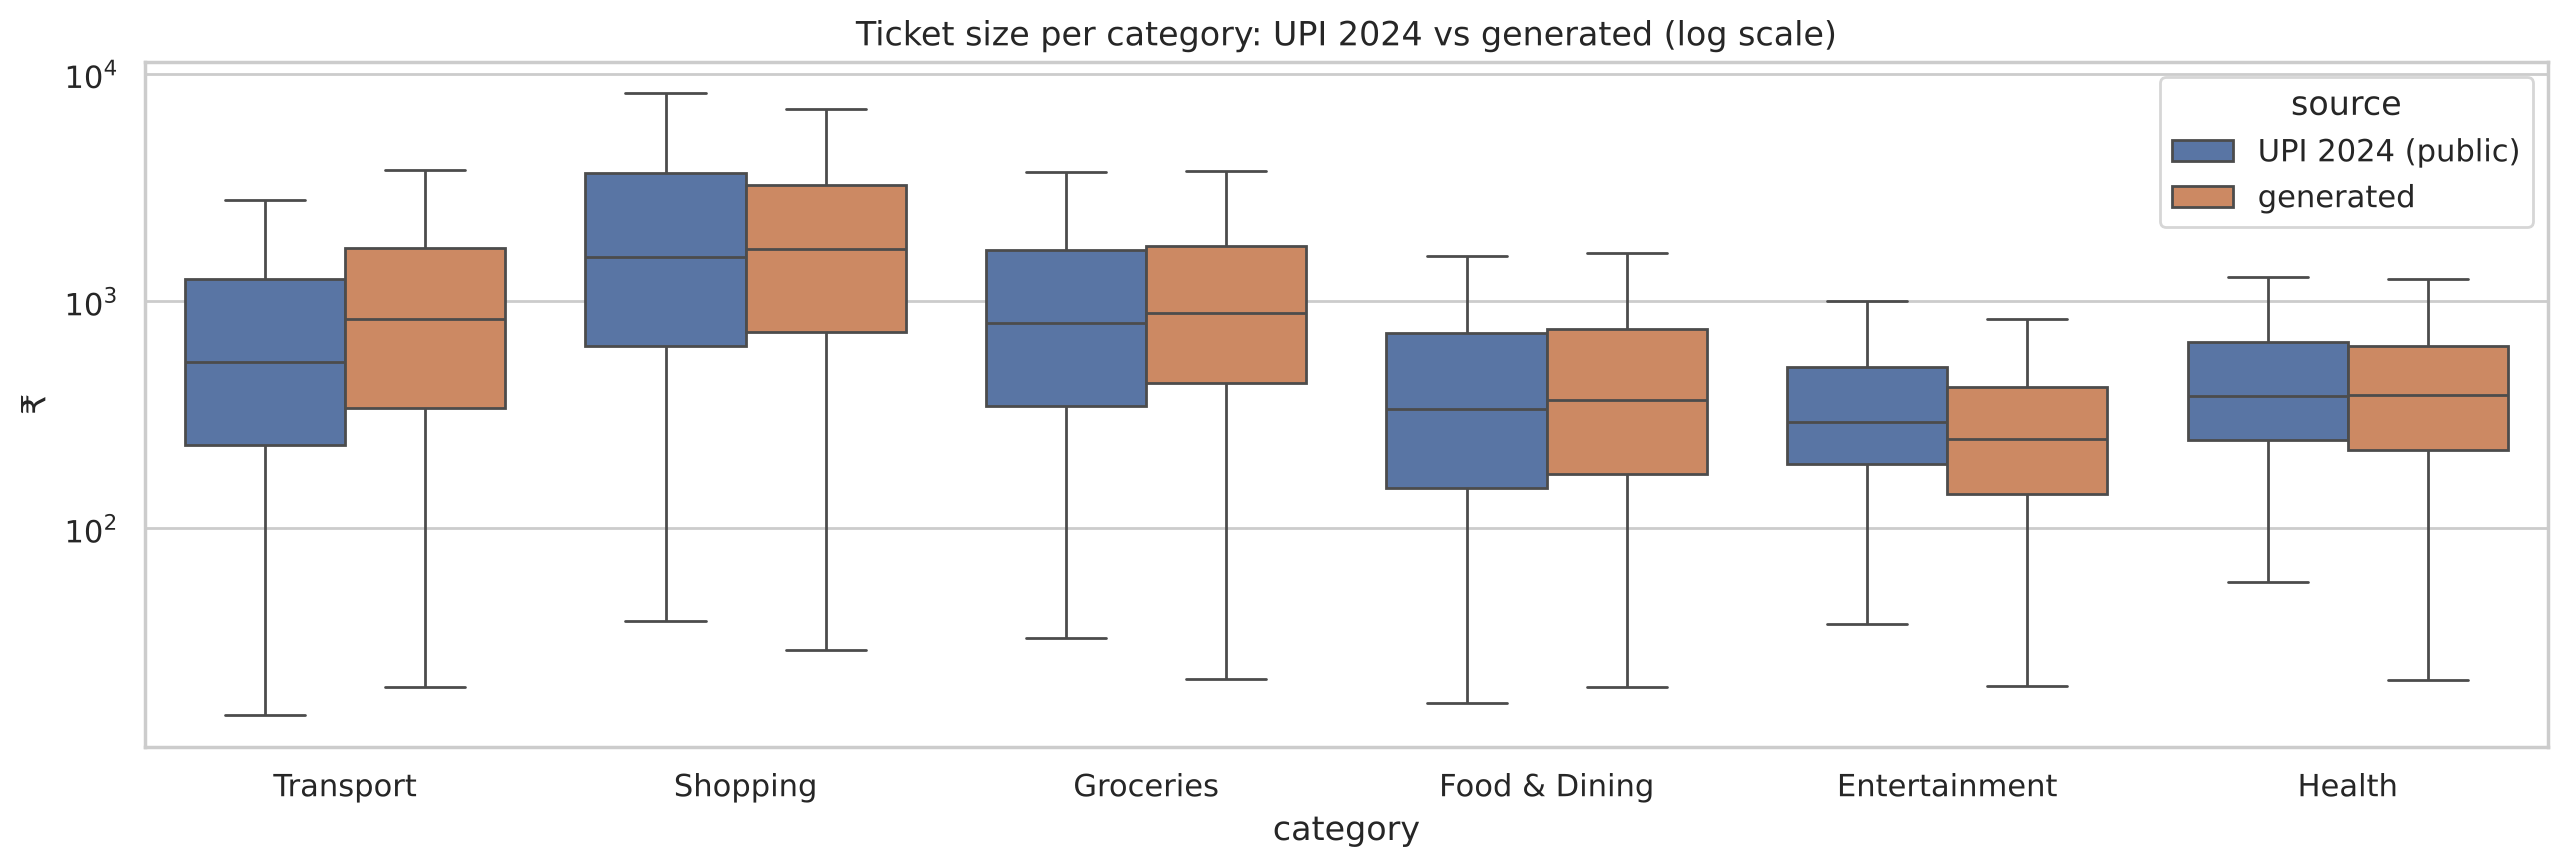

,UPI median,generated median
category,,
Entertainment,294.0,258.0
Food & Dining,332.0,366.0
Groceries,819.0,891.0
Health,386.0,381.0
Shopping,1566.0,1700.0
Transport,539.0,822.0


UPI weekend-to-weekday ratio of transactions per category (1.0 = no weekend effect):


,Bills & Utilities,Education,Entertainment,Food & Dining,Groceries,Health,Others,Shopping,Transport
weekend_ratio,0.988,1.052,0.997,0.988,0.998,0.995,0.981,1.002,1.0


In [7]:
# #2 UPI 2024: real ticket sizes per category vs our generated (calibrated) variable-spend transactions
upi = public.get('upi_2024')
if upi is not None:
    u = upi[upi.transaction_status == 'SUCCESS'].assign(category=lambda d: d.merchant_category.map(UPI_CATEGORY_MAP))
    cats = ['Food & Dining', 'Groceries', 'Transport', 'Shopping', 'Health', 'Entertainment']
    a = u[u.category.isin(cats)][['category', 'amount (INR)']].rename(columns={'amount (INR)': 'amount'}).assign(source='UPI 2024 (public)')
    g = debit[debit.category.isin(cats) & ~debit.is_large][['category', 'amount']].assign(source='generated')
    both = pd.concat([a.sample(40000, random_state=42), g.sample(40000, random_state=42)])
    plt.figure(figsize=(13, 4.5)); sns.boxplot(data=both, x='category', y='amount', hue='source', showfliers=False)
    plt.yscale('log'); plt.title('Ticket size per category: UPI 2024 vs generated (log scale)'); plt.ylabel('₹')
    plt.tight_layout(); plt.savefig(RES / 'eda_upi_vs_generated_amounts.png', dpi=110); plt.show()
    med = pd.DataFrame({'UPI median': a.groupby('category').amount.median(), 'generated median': g.groupby('category').amount.median()}).round(0)
    display(med)
    print('UPI weekend-to-weekday ratio of transactions per category (1.0 = no weekend effect):')
    display(upi_calibration()[['weekend_ratio']].round(3).T)

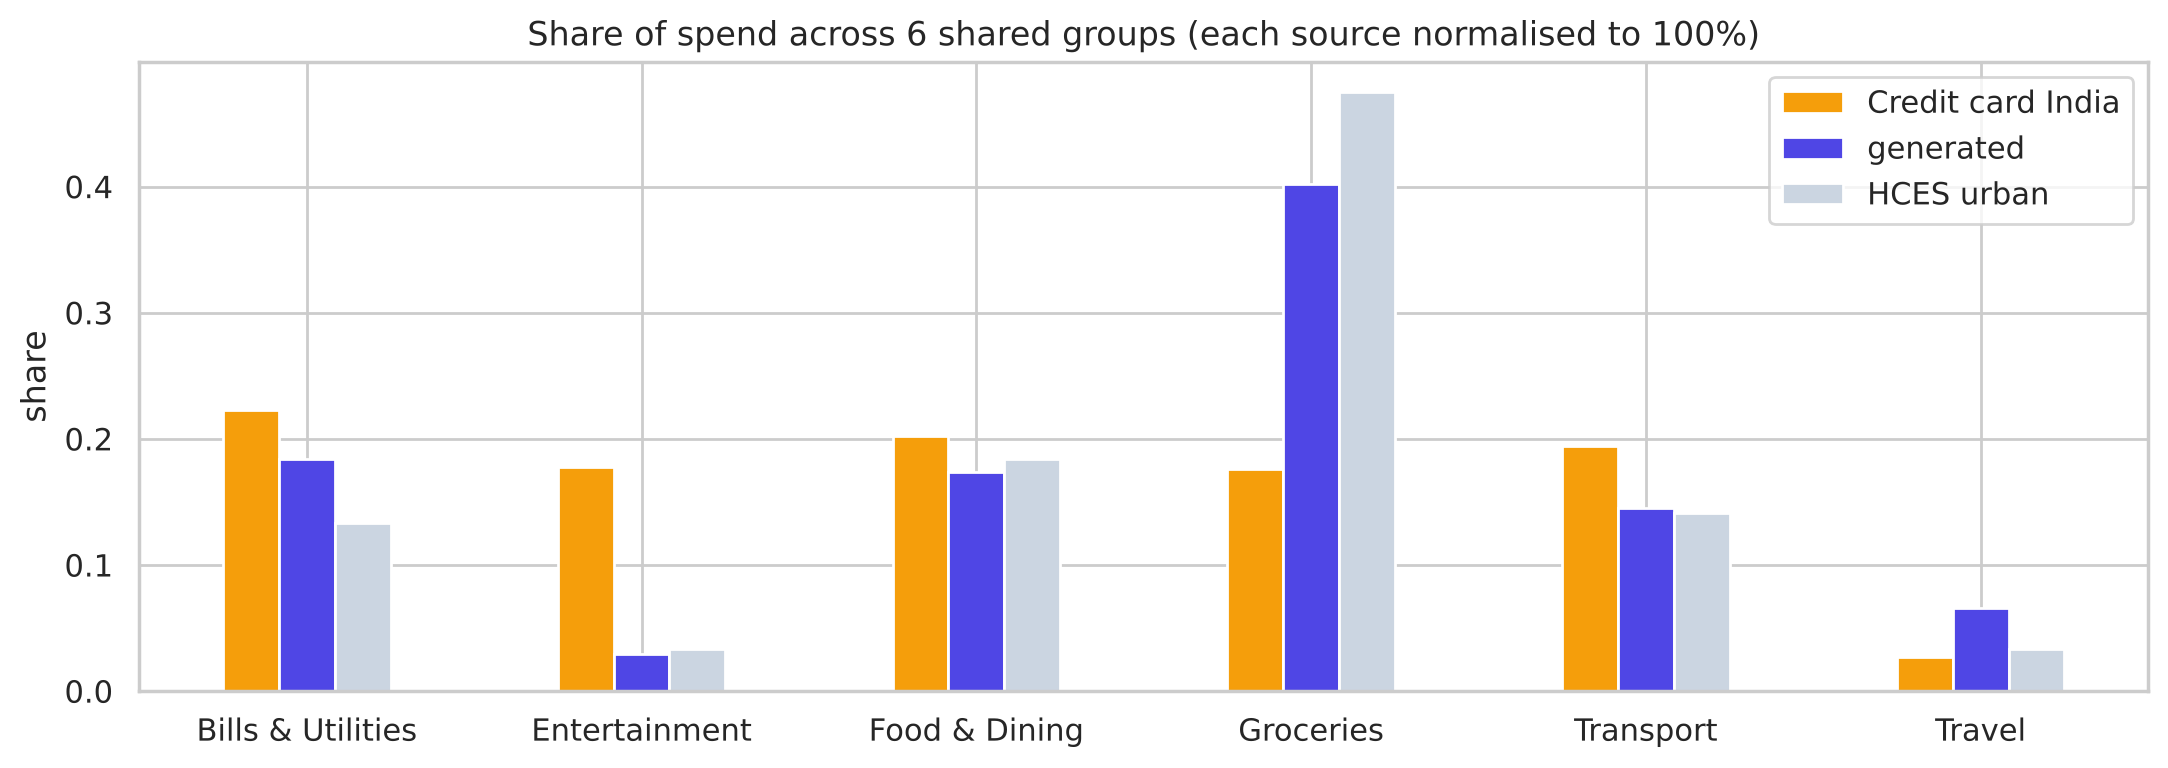

,Credit card India,generated,HCES urban
Bills & Utilities,0.223,0.184,0.133
Entertainment,0.178,0.029,0.033
Food & Dining,0.202,0.174,0.184
Groceries,0.176,0.402,0.475
Transport,0.194,0.145,0.141
Travel,0.027,0.066,0.033


In [8]:
# #3 Credit-card spending India: share of spend by expense type vs generated vs HCES (6 overlapping groups)
cc = public.get('credit_card_india')
if cc is not None:
    cc_map = {'Food': 'Food & Dining', 'Grocery': 'Groceries', 'Fuel': 'Transport', 'Bills': 'Bills & Utilities',
              'Entertainment': 'Entertainment', 'Travel': 'Travel'}
    groups = list(cc_map.values())
    cc_share = cc.assign(category=cc['Exp Type'].map(cc_map)).groupby('category').Amount.sum()
    gen = debit[debit.category.isin(groups)].groupby('category').amount.sum()
    hces = pd.Series(HCES_URBAN_SHARES)[groups]
    tab = pd.DataFrame({'Credit card India': cc_share / cc_share.sum(), 'generated': gen / gen.sum(), 'HCES urban': hces / hces.sum()}).round(3)
    tab.plot.bar(figsize=(11, 4), color=['#F59E0B', '#4F46E5', '#CBD5E1'], rot=0,
                 title='Share of spend across 6 shared groups (each source normalised to 100%)'); plt.ylabel('share')
    plt.tight_layout(); plt.savefig(RES / 'eda_share_comparison_public.png', dpi=110); plt.show()
    display(tab)

### Findings and Decisions
**What I saw**
- 15 expense categories, **imbalanced**: Food & Dining has ~11.6× more transactions than the smallest category. Accuracy alone would be misleading.
- Amounts are heavily right-skewed (rent, EMIs, one-off purchases); `log(1 + amount)` is close to symmetric.
- UPI dominates (~58% of rows), then card and POS; ACH/NACH appears almost only for EMIs, SIPs and insurance, so payment mode carries category signal.
- No missing values or exact duplicates after cleaning; reference numbers, VPAs and dataset #1's `txn_###` ids are removed.
- Top tokens per category are merchant names, but ~5% of rows are person-to-person UPI payments whose text says nothing about the category.
- **Public #1 (HF)**: its 7 coarse labels disagree with our taxonomy for some merchants (Blinkit = "Food", Netflix = "Entertainment", Gym = "Health"), so it is mapped per merchant. Its descriptions are clean merchant names with no bank prefixes.
- **Public #2 (UPI 2024)**: after calibration, generated median ticket sizes are within ~10% of UPI for Food, Groceries, Health, Entertainment and Shopping. Transport is higher (₹822 vs ₹539) because ours includes fixed FASTag/metro top-ups.
- **Public #3 (credit card India)**: spend is split almost evenly across its five main expense types (18-22% each), unlike HCES, where groceries dominate. That looks artificially balanced.
- Generated shares track HCES for most groups. Rent is higher (16% vs 6.6%) because HCES averages in homeowners, and Groceries is correspondingly lower.

**Decisions**
- Primary metric **macro F1**. Compare `class_weight="balanced"` and **SMOTE** (inside the pipeline) against no reweighting.
- Features: word 1-2-gram + **character 2-5-gram TF-IDF** (robust to typos and truncation), `log_amount`, payment mode, day of week.
- Use dataset #1 for extra training rows **and** an external test, holding out half of its new merchants entirely so the test also measures unseen merchants.
- Keep HCES (official) for category shares and use UPI 2024 only for ticket sizes. Dataset #3 is a cross-check, not a calibration source.
- **Confidence threshold** so ambiguous P2P payments are flagged *Needs review*; large amounts are **flagged, not deleted**.

## 2. Subscriptions

rows: 26597  positive share: 0.071


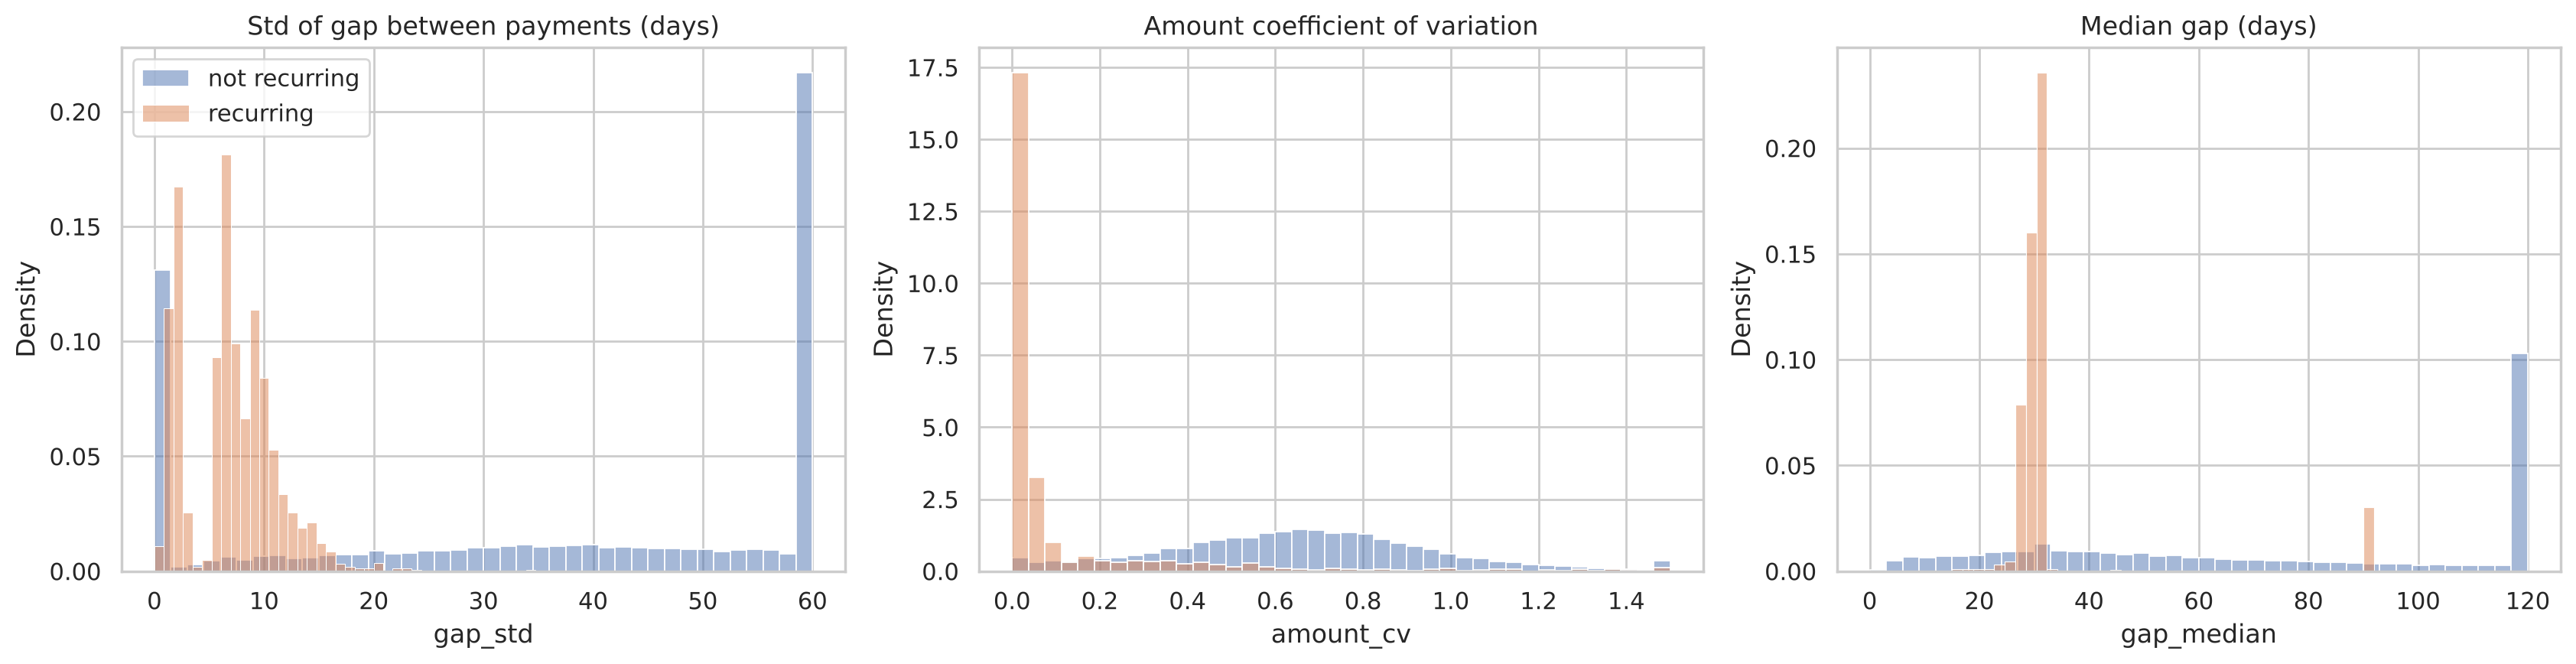

is_recurring,0,1
n_payments,6.000,23.000
gap_mean,83.000,31.682
gap_median,66.000,30.500
gap_std,40.139,6.829
gap_cv,0.696,0.220
amount_mean,731.219,997.992
amount_cv,0.656,0.003
same_amount_share,0.032,1.000
dom_std,7.923,1.419
months_active,6.000,23.000


In [9]:
sub = F.subscription_features(df).merge(labels, on=['user_id','merchant'], how='left')
sub['is_recurring'] = sub.is_recurring.fillna(0).astype(int)
print('rows:', len(sub), ' positive share:', round(sub.is_recurring.mean(), 3))
fig, ax = plt.subplots(1, 3, figsize=(17, 4.5))
for k, g in sub.groupby('is_recurring'):
    lab = 'recurring' if k else 'not recurring'
    sns.histplot(g.gap_std.clip(upper=60), bins=40, ax=ax[0], label=lab, stat='density', alpha=.5)
    sns.histplot(g.amount_cv.clip(upper=1.5), bins=40, ax=ax[1], label=lab, stat='density', alpha=.5)
    sns.histplot(g.gap_median.clip(upper=120), bins=40, ax=ax[2], label=lab, stat='density', alpha=.5)
ax[0].set(title='Std of gap between payments (days)'); ax[1].set(title='Amount coefficient of variation'); ax[2].set(title='Median gap (days)')
ax[0].legend(); plt.tight_layout(); plt.savefig(RES / 'eda_subscription_features.png', dpi=110); plt.show()
sub.groupby('is_recurring')[F.SUB_FEATURES].median().T.round(3)

In [10]:
print('Hard negatives (non-recurring with near-fixed amounts):')
print(sub[(sub.is_recurring == 0) & (sub.same_amount_share > .8) & (sub.n_payments >= 3)].merchant.value_counts().head(8))
print('\nHard positives (recurring with varying amounts or irregular gaps):')
print(sub[(sub.is_recurring == 1) & ((sub.amount_cv > .05) | (sub.gap_std > 10))].merchant.value_counts().head(8))

Hard negatives (non-recurring with near-fixed amounts):
merchant
INDANE GAS      61
HP GAS          59
BMTC            47
DELHI METRO     47
FASTAG          36
PAYTM WALLET    32
AMAZON PAY      23
AIRTEL           8
Name: count, dtype: int64

Hard positives (recurring with varying amounts or irregular gaps):
merchant
AIRTEL POSTPAID    103
AIRTEL XSTREAM      71
AIRTEL              58
APPLE SERVICES      52
ACT FIBERNET        51
CULT FIT            48
AMAZON PRIME        43
SONYLIV             42
Name: count, dtype: int64


### Findings and Decisions
**What I saw**
- ~26.6k (user, merchant) groups with ≥2 payments; only **7.1% are recurring**, so the problem is strongly imbalanced.
- Recurring payments have small gap std (median ~7 days vs ~40), near-zero amount CV and `same_amount_share` ≈ 1.
- Hard negatives exist: LPG refills, wallet and FASTag top-ups have **fixed amounts but irregular timing**. Hard positives: postpaid and broadband bills with varying amounts, 28-day prepaid cycles, missed months, recently started subscriptions.

**Decisions**
- Use both **timing** (gap mean/median/std/CV, day-of-month std, longest missing stretch) and **amount** features (CV, same-amount share), because neither alone separates hard cases.
- Primary metric **F1 on the positive class**, plus PR-AUC (better than ROC-AUC under imbalance). Compare class weights / `scale_pos_weight` / **SMOTE**.
- CV **grouped by user** so the same person never appears in both train and validation.
- The near-perfect separation in this synthetic data is a warning sign: report it as an upper bound, not real-world performance.

## 3. Monthly spending

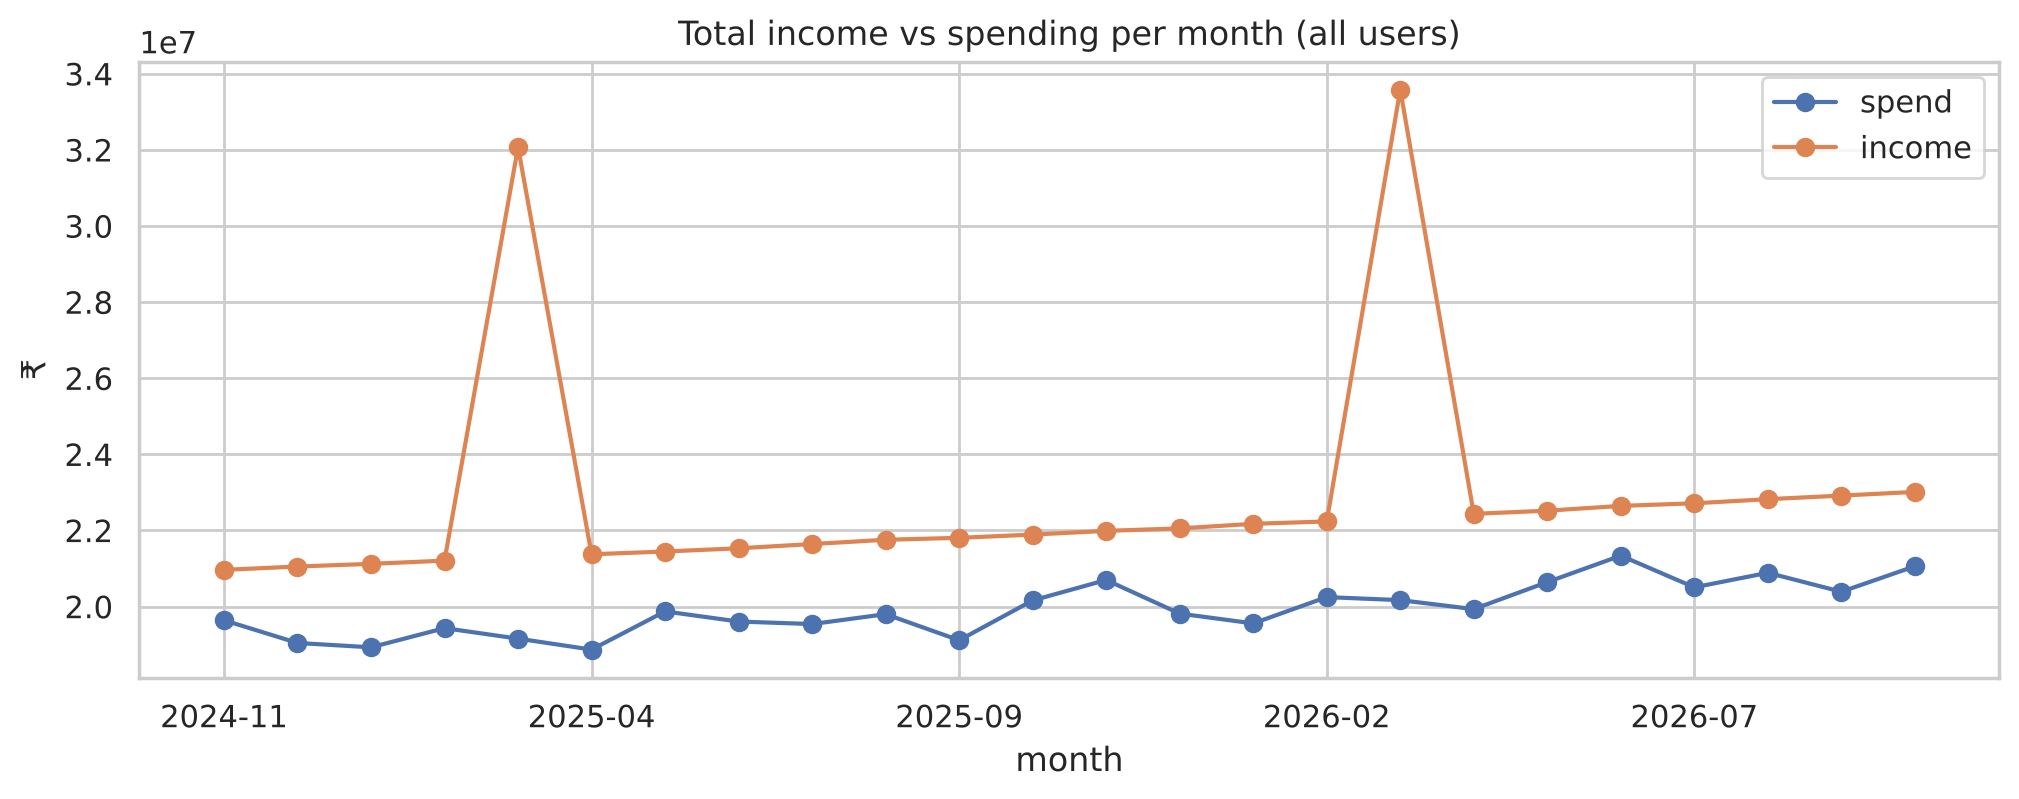

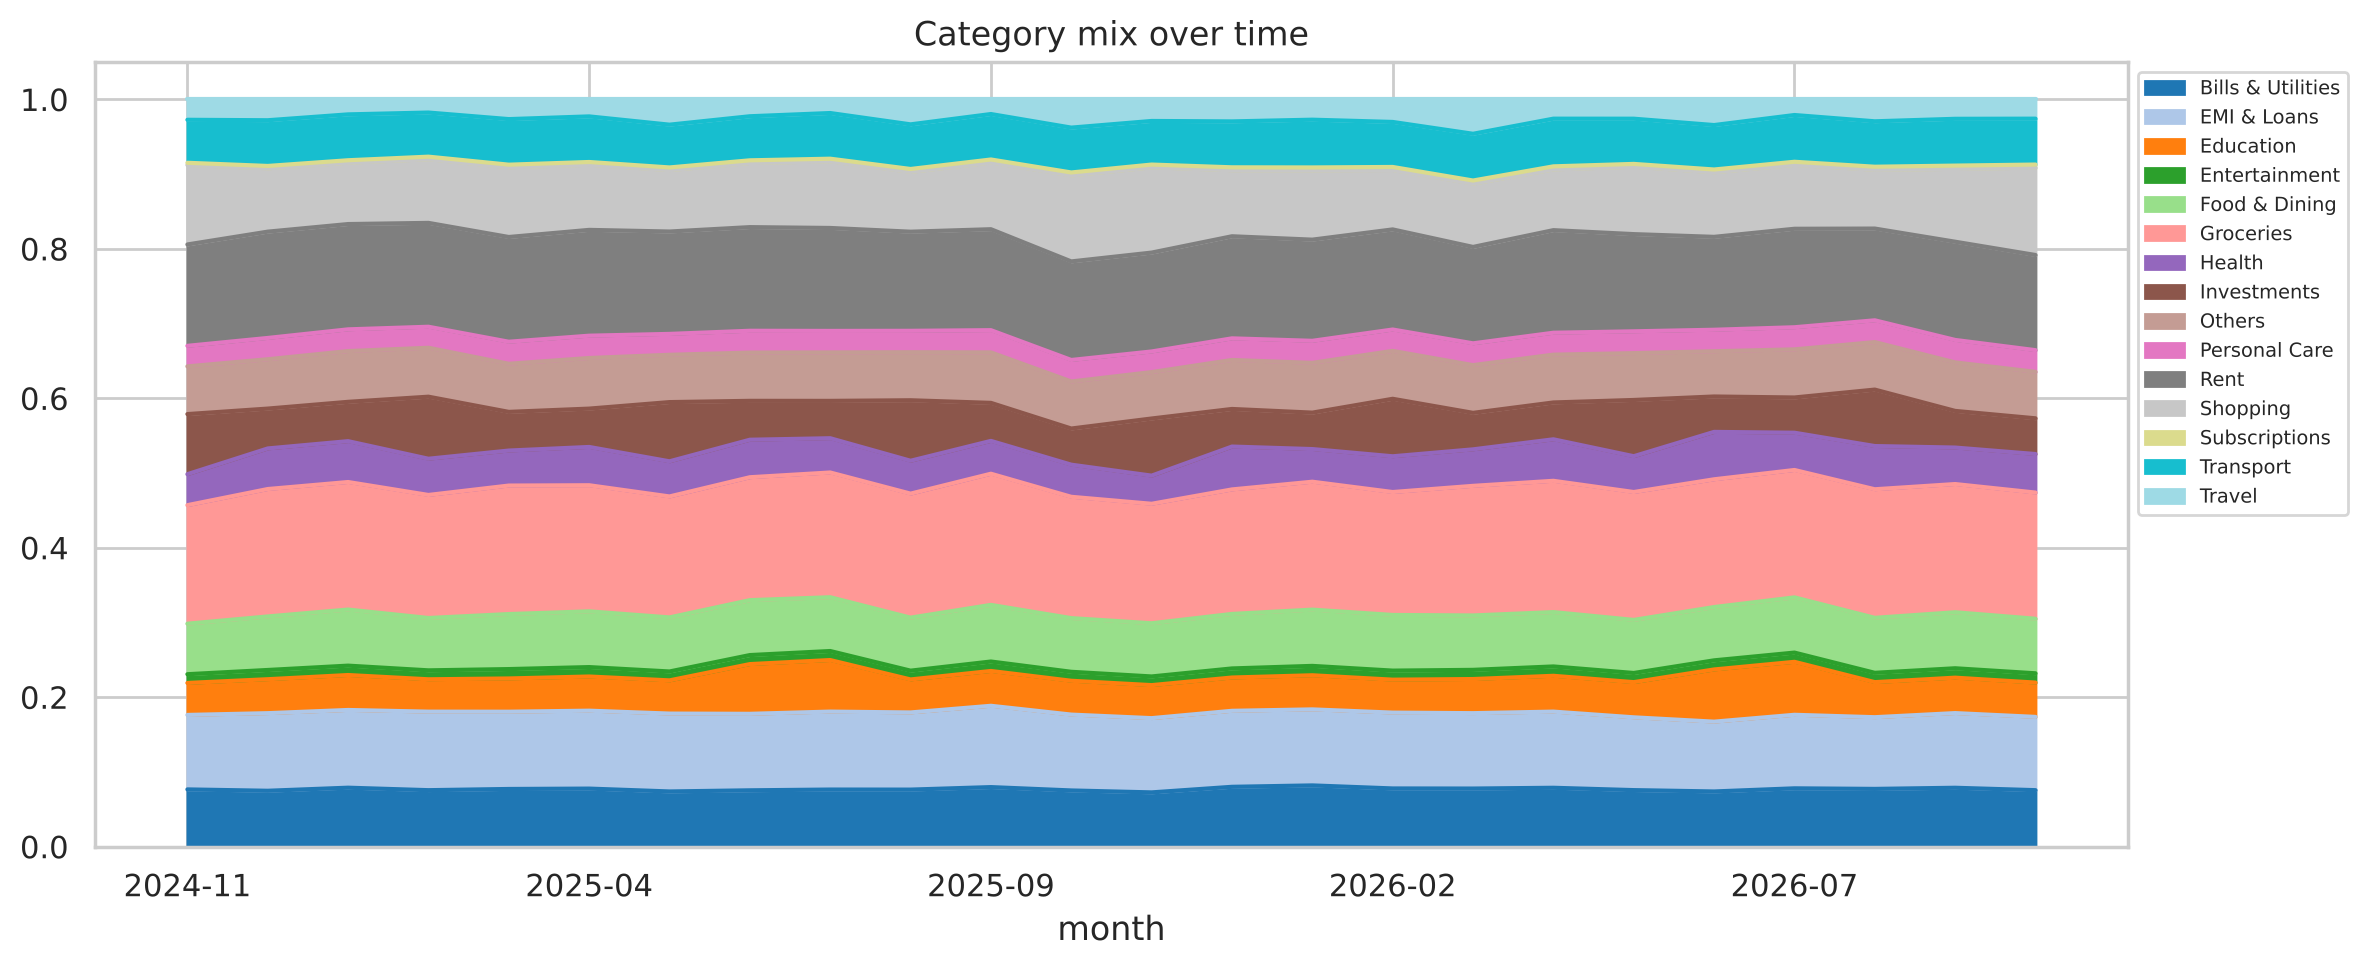

In [11]:
m = F.monthly_table(df)
tot = m.groupby('month').agg(spend=('spend', 'sum')).join(m.drop_duplicates(['user_id','month']).groupby('month').income.sum())
tot.index = tot.index.astype(str)
tot.plot(figsize=(12, 4), marker='o', title='Total income vs spending per month (all users)'); plt.ylabel('₹'); plt.show()
cat_trend = m.groupby(['month', 'category']).spend.sum().unstack()
cat_trend.index = cat_trend.index.astype(str)
(cat_trend / cat_trend.sum(axis=1).values[:, None]).plot.area(figsize=(12, 5), cmap='tab20', title='Category mix over time')
plt.legend(bbox_to_anchor=(1, 1), fontsize=7); plt.tight_layout(); plt.savefig(RES / 'eda_category_mix.png', dpi=110); plt.show()

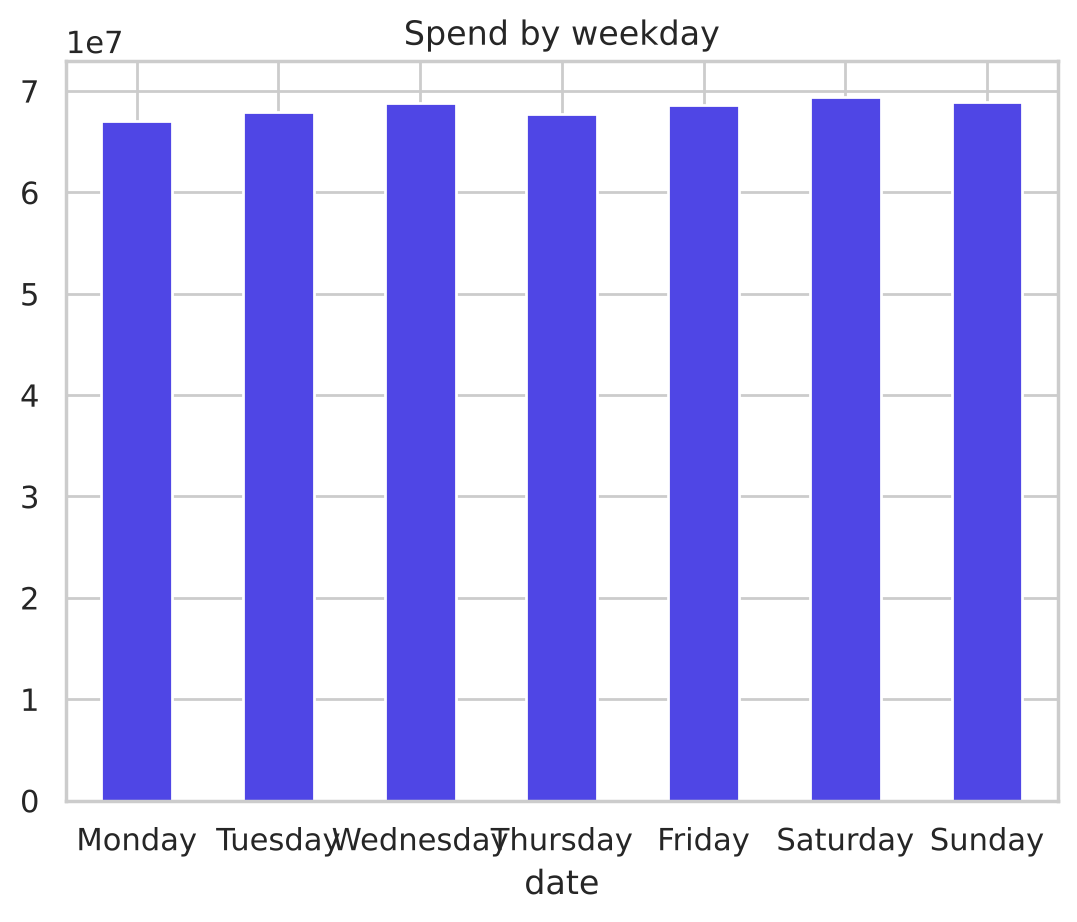

Correlation of next-month spend with lags:
target        1.000
lag1          0.790
lag2          0.788
lag3          0.793
lag12         0.818
roll3_mean    0.852
Name: target, dtype: float64

Lag-1 autocorrelation by category:
category
Travel               0.04
Health               0.14
Shopping             0.38
Investments          0.88
Transport            0.88
Education            0.91
Bills & Utilities    0.92
Others               0.92
Personal Care        0.94
Rent                 0.94
Food & Dining        0.94
Groceries            0.95
Subscriptions        0.95
Entertainment        0.95
EMI & Loans          0.98
dtype: float64


In [12]:
wd = df[df.type == 'debit'].groupby(df.date.dt.day_name()).amount.sum()
wd.reindex(['Monday','Tuesday','Wednesday','Thursday','Friday','Saturday','Sunday']).plot.bar(title='Spend by weekday', color='#4F46E5', rot=0); plt.show()
ff = F.forecast_features(m)
corr = ff[['target', 'lag1', 'lag2', 'lag3', 'lag12', 'roll3_mean']].corr()['target'].round(3)
print('Correlation of next-month spend with lags:'); print(corr)
per_cat = ff.groupby('category').apply(lambda g: g['target'].corr(g['lag1']), include_groups=False).sort_values()
print('\nLag-1 autocorrelation by category:'); print(per_cat.round(2))

### Findings and Decisions
**What I saw**
- Totals grow slowly over 24 months (income trend), with mild seasonality: Shopping in Oct-Nov, Travel in May/Dec, Education in Jun-Jul.
- Next-month spend correlates with lag 1, 2 and 3 (~0.79 each), more with the **3-month rolling mean (0.85)** and with **lag 12 (0.82)**.
- Lag-1 autocorrelation is very high for fixed or regular categories (EMI 0.98, Subscriptions 0.95, Rent 0.94) and very low for lumpy ones (**Travel 0.04, Health 0.14, Shopping 0.38**), which are the hardest to forecast.
- **No weekend effect**: public UPI 2024 shows weekend-to-weekday transaction ratios of 0.98-1.05 in every category. The generator follows the data, so weekday spending is flat.

**Decisions**
- Features: lags 1-3, rolling 3-month mean/std, **same-month-last-year** (with a has-lag-12 flag), transaction count, average ticket, income, spend-to-income ratio, target month as sin/cos, and category one-hot. No festival features.
- Two baselines: last month and 3-month mean (the stronger one, as EDA predicts). Use a chronological split.
- Expect large per-category errors for Travel/Health/Shopping and show a forecast range (validation residual quantiles).

## 4. Users

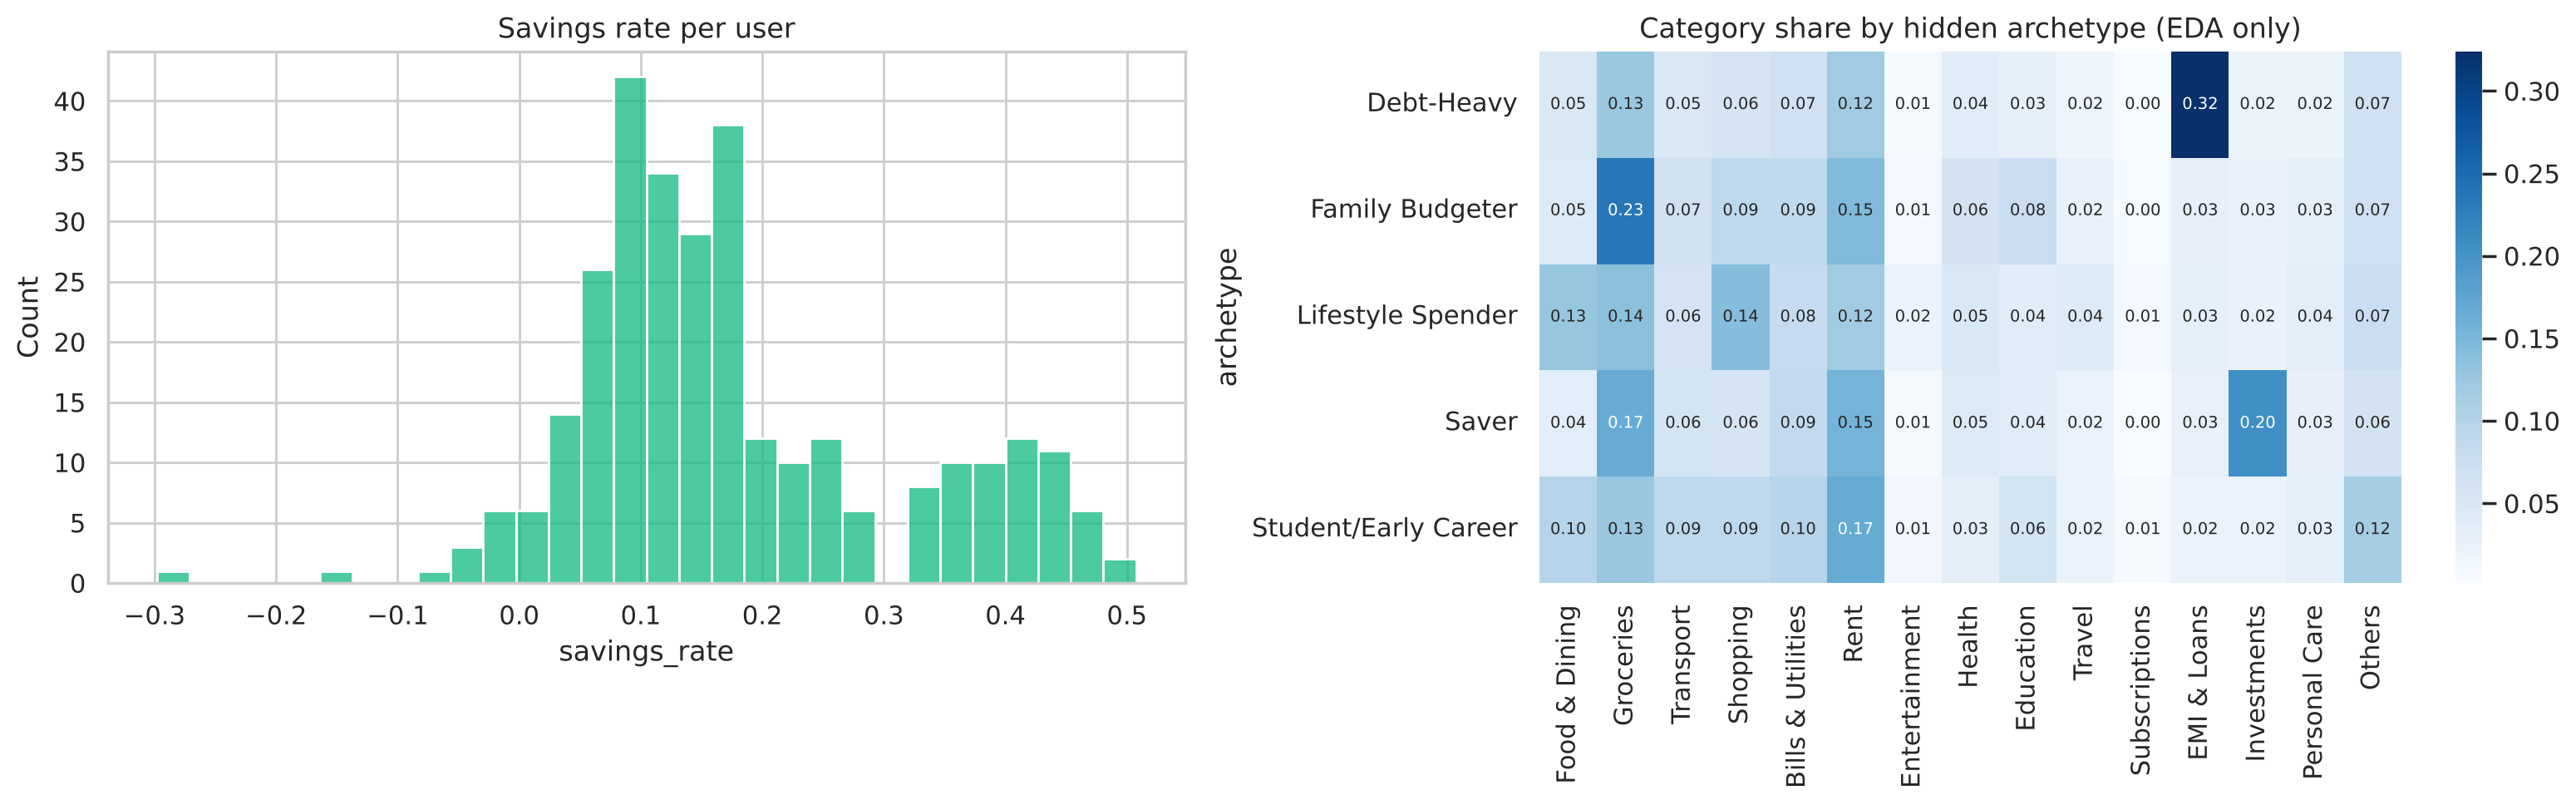

In [13]:
pf = F.persona_features(df).merge(users, on='user_id')
fig, ax = plt.subplots(1, 2, figsize=(16, 5))
sns.histplot(pf.savings_rate, bins=30, ax=ax[0], color='#10B981'); ax[0].set(title='Savings rate per user')
share = pf.groupby('archetype')[F.PERSONA_SHARE_COLS].mean(); share.columns = [c.replace('share_', '') for c in share.columns]
sns.heatmap(share, cmap='Blues', ax=ax[1], annot=True, fmt='.2f', annot_kws={'size': 7}); ax[1].set(title='Category share by hidden archetype (EDA only)')
plt.tight_layout(); plt.show()

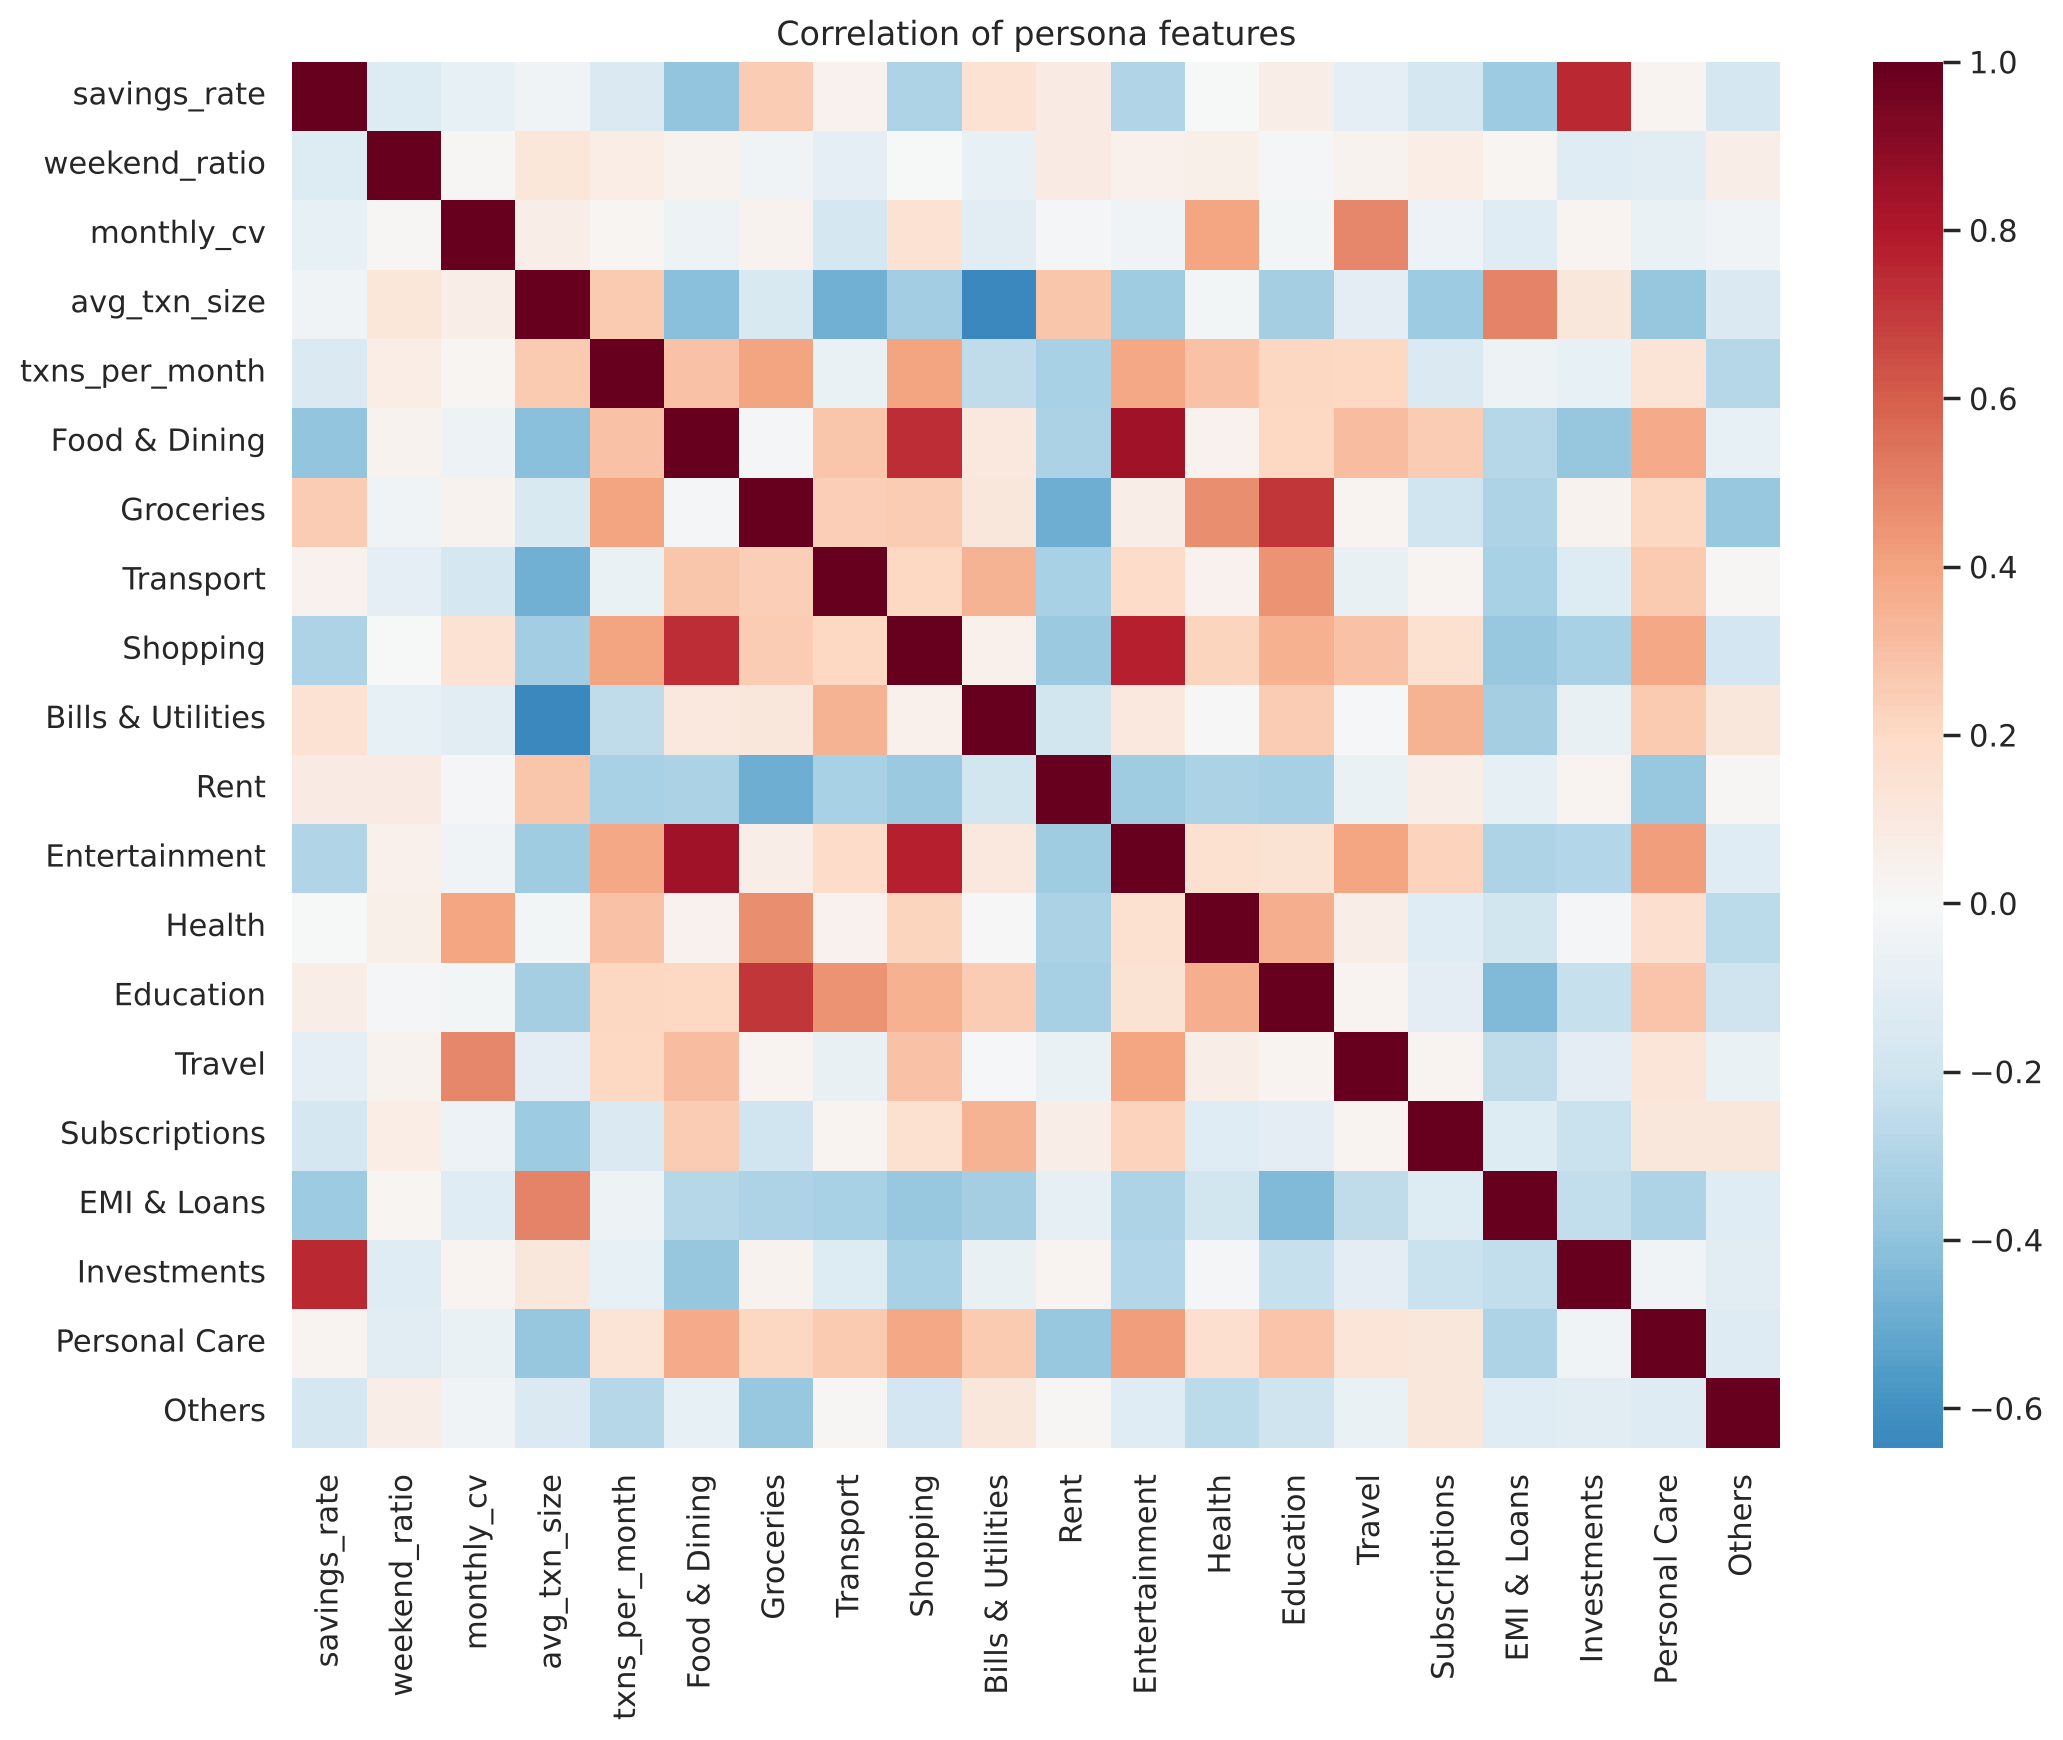

Skewness:
savings_rate      0.56
weekend_ratio     0.21
monthly_cv        0.05
avg_txn_size      1.61
txns_per_month    1.61
dtype: float64


In [14]:
plt.figure(figsize=(12, 9))
sns.heatmap(pf[F.PERSONA_FEATURES].corr(), cmap='RdBu_r', center=0, xticklabels=[c.replace('share_', '') for c in F.PERSONA_FEATURES],
            yticklabels=[c.replace('share_', '') for c in F.PERSONA_FEATURES]); plt.title('Correlation of persona features'); plt.show()
print('Skewness:'); print(pf[F.PERSONA_NUM].skew().round(2))

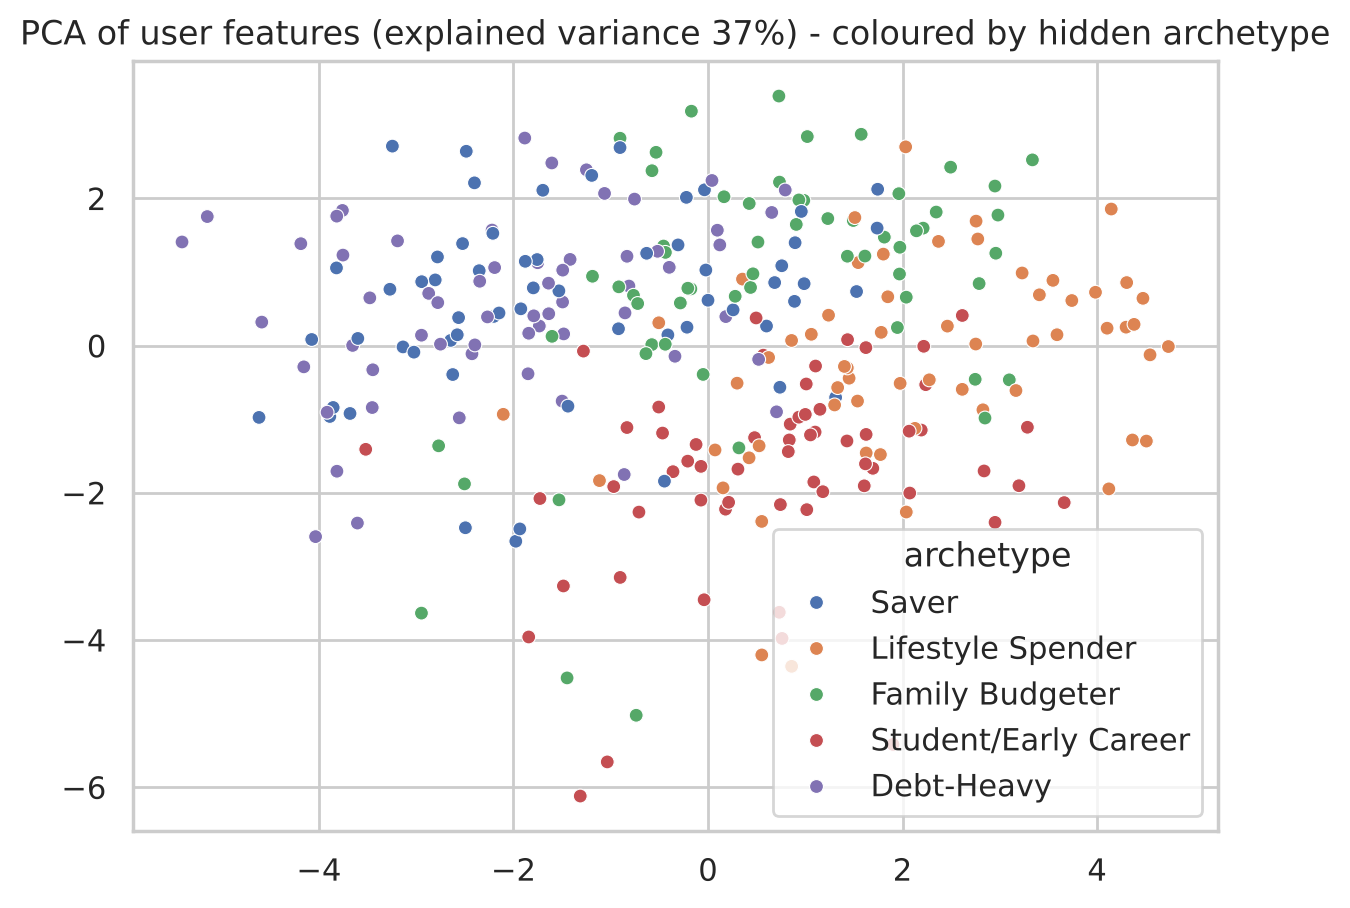

In [15]:
from sklearn.decomposition import PCA
X = F.persona_preprocessor().fit_transform(pf[F.PERSONA_FEATURES])
pca = PCA(2).fit(X); pc = pca.transform(X)
plt.figure(figsize=(7, 5)); sns.scatterplot(x=pc[:, 0], y=pc[:, 1], hue=pf.archetype, s=25)
plt.title(f'PCA of user features (explained variance {pca.explained_variance_ratio_.sum():.0%}) - coloured by hidden archetype')
plt.savefig(RES / 'eda_users_pca.png', dpi=110); plt.show()

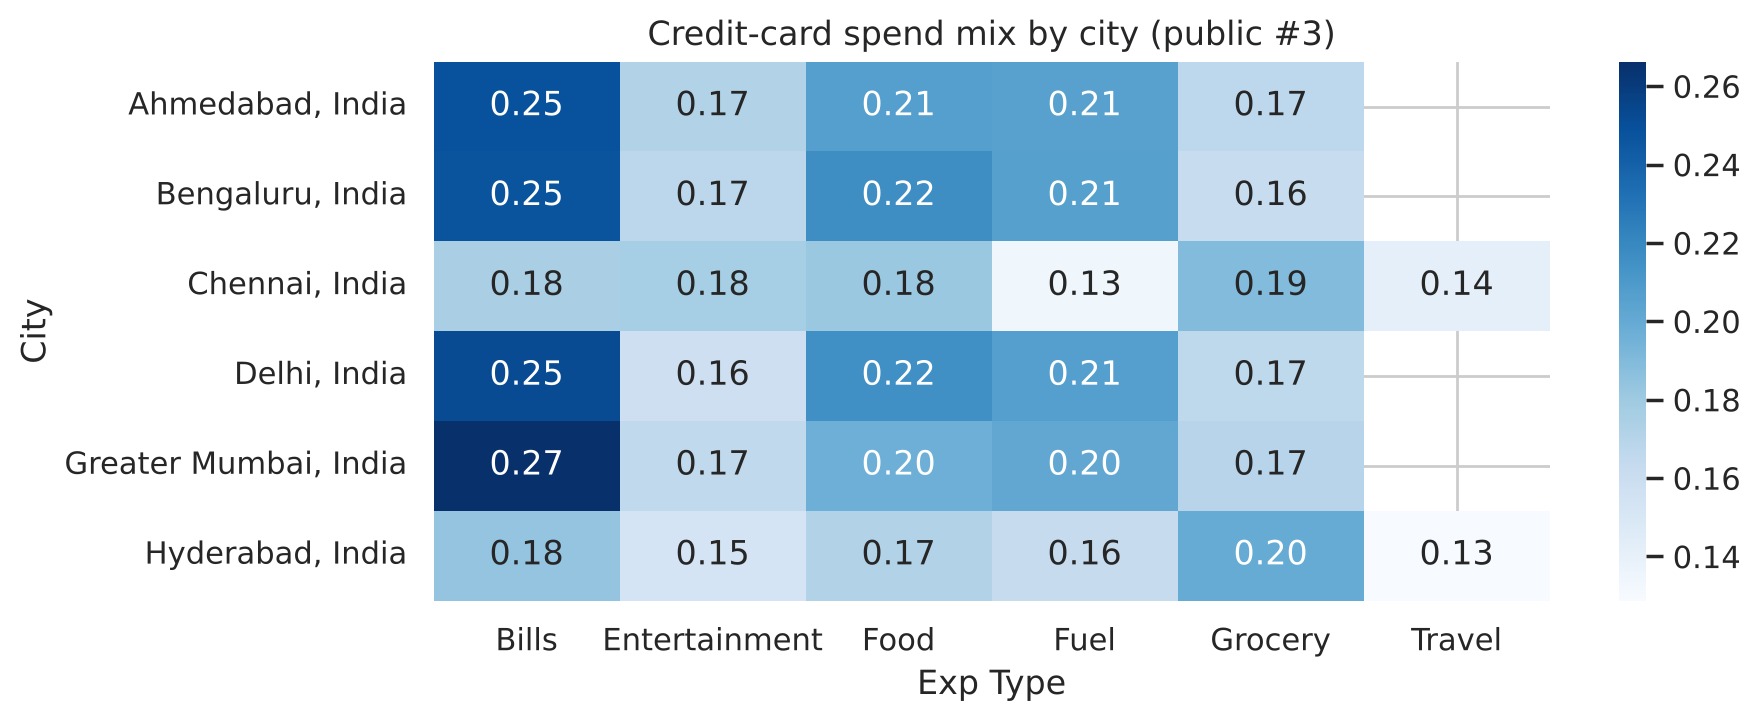

Exp Type,Bills,Entertainment,Food,Fuel,Grocery,Travel
Card Type,,,,,,
Gold,0.229,0.176,0.197,0.197,0.169,0.032
Platinum,0.220,0.184,0.209,0.193,0.170,0.024
Signature,0.223,0.176,0.204,0.185,0.184,0.027
Silver,0.218,0.176,0.200,0.199,0.181,0.025


In [16]:
# Cross-check with public dataset #3: do spending mixes differ across groups (cities, card types)?
if cc is not None:
    top = cc.City.value_counts().head(6).index
    mix = cc[cc.City.isin(top)].pivot_table(index='City', columns='Exp Type', values='Amount', aggfunc='sum')
    mix = mix.div(mix.sum(axis=1), axis=0)
    plt.figure(figsize=(9, 3.5)); sns.heatmap(mix, annot=True, fmt='.2f', cmap='Blues'); plt.title('Credit-card spend mix by city (public #3)'); plt.show()
    card = cc.pivot_table(index='Card Type', columns='Exp Type', values='Amount', aggfunc='sum'); card = card.div(card.sum(axis=1), axis=0)
    display(card.round(3))

### Findings and Decisions
**What I saw**
- Savings rate ranges from about 0 to 45% (skew 0.56). Average ticket size and transactions per month are strongly skewed (1.61 each).
- Category shares differ clearly by (hidden) archetype: EMI share for Debt-Heavy, Investments for Savers, Dining/Shopping/Travel for Lifestyle Spenders, Education/Groceries for Family Budgeters.
- Several share features are correlated (for example Dining with Entertainment), but none is redundant enough to drop.
- In the 2-D PCA projection, archetypes form visible but overlapping groups.
- **Public #3 cross-check**: spend mix is almost identical across card types (within ±1-2 points) and similar across most large cities (Bills ~25%, Food ~20%). The main difference is that Travel spending appears only in some cities (Chennai and Hyderabad at 13-14%, while Delhi, Mumbai, Bengaluru and Ahmedabad have none). Groups differ mostly in one or two categories rather than overall, a reminder that real personas overlap.
- Weekend ratio carries little signal, because there is no weekend effect in the UPI-calibrated data.

**Decisions**
- Log-transform skewed features (average ticket, transactions per month, weekend ratio), then `StandardScaler`, all inside one pipeline.
- Try K-Means, Gaussian Mixture and Agglomerative for k = 2-8, selecting on **silhouette**. Reject solutions with a cluster under 5% of users, and require k ≥ 3 so personas are useful.
- Archetypes are used **only** for a post-hoc ARI check, never as features.